# 02 - Is the task learnable? Sanity checks and label reliability
**Run `memotion_fusion.ipynb` first** - this notebook reuses its cached CLIP/RoBERTa features
(`outputs/cache/hf/`) and needs no GPU. It answers why every model in the main notebook stays
close to chance:
1. **Pipeline check** - are features and labels aligned? CLIP should retrieve each meme's own text.
2. **Linear probes** - can the frozen features predict *any* Memotion label (cross-validated ROC-AUC)?
3. **Annotation consistency** - do near-identical memes receive the same sentiment label?

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import src  # applies the macOS fixes (PyTorch before scikit-learn)
from src.config import Config
from src import data as D, plots as P, reliability as RL

P.set_style()
DATA_PATH = "data"   # same value as in memotion_fusion.ipynb (or the kagglehub path)
try:
    import kagglehub
    DATA_PATH = kagglehub.dataset_download("williamscott701/memotion-dataset-7k")
except Exception:
    pass
cfg = Config(data_path=DATA_PATH)

## 1. Rebuild the same data frame and load the cached features

In [2]:
labels_csv, images_dir = D.locate_dataset(cfg.data_path)
df = D.load_labels(labels_csv, images_dir)
df = D.inspect_images(df)
df = df[df["readable"]].reset_index(drop=True)

import hashlib
key = hashlib.md5("|".join(df["image_name"]).encode()).hexdigest()[:8]
cache = cfg.cache_dir / cfg.encoder_backend
FEATS = {name: np.load(cache / f"{name}_{key}.npz")["x"] for name in ("clip_img", "clip_txt", "roberta_txt")}
print(len(df), "memes |", {k: v.shape for k, v in FEATS.items()})

6991 memes | {'clip_img': (6991, 512), 'clip_txt': (6991, 512), 'roberta_txt': (6991, 768)}


## 2. Pipeline check: image-to-text retrieval
If rows were misaligned, CLIP could not find a meme's own caption among 1,000 candidates.

In [3]:
RET = RL.retrieval_check(FEATS["clip_img"], FEATS["clip_txt"])
display(pd.Series(RET).to_frame("value"))

,value
n,1000.000000
top1,0.726000
top5,0.863000
chance_top1,0.001000
cos_own_pair,0.320983
cos_shuffled_pair,0.194386


## 3. Linear probes on every Memotion label
Logistic regression (standardised features, balanced class weights, C = 0.1), 5-fold stratified CV
repeated twice. ROC-AUC 0.5 means the features carry no usable signal for that label.

In [4]:
probe_feats = {"CLIP image": FEATS["clip_img"], "CLIP text": FEATS["clip_txt"],
               "RoBERTa text": FEATS["roberta_txt"],
               "CLIP image+text": np.hstack([FEATS["clip_img"], FEATS["clip_txt"]])}
PROBE = RL.linear_probe_auc(probe_feats, df)
display(PROBE.pivot(index="target", columns="features", values="auc_mean").round(3))
PROBE.to_csv(cfg.table_dir / "label_probe_auc.csv", index=False)

features,CLIP image,CLIP image+text,CLIP text,RoBERTa text
target,,,,
Humour: not funny,0.544,0.533,0.514,0.519
Motivational,0.511,0.509,0.521,0.507
Offensive (very/hateful),0.520,0.518,0.514,0.504
Sarcasm: not sarcastic,0.504,0.499,0.498,0.499
Sentiment: negative vs rest,0.511,0.517,0.525,0.501
Sentiment: positive vs rest,0.497,0.503,0.507,0.507
Sentiment: very pos. vs very neg.,0.504,0.537,0.501,0.485


## 4. Annotation consistency

,pair_type,n_pairs,same_label_pct,chance_pct
0,Image cosine ≥ 0.98,45,60.0,46.1
1,Image cosine ≥ 0.95,62,54.8,46.1
2,Image cosine ≥ 0.9,268,53.4,46.1
3,Identical text,81,54.3,46.1


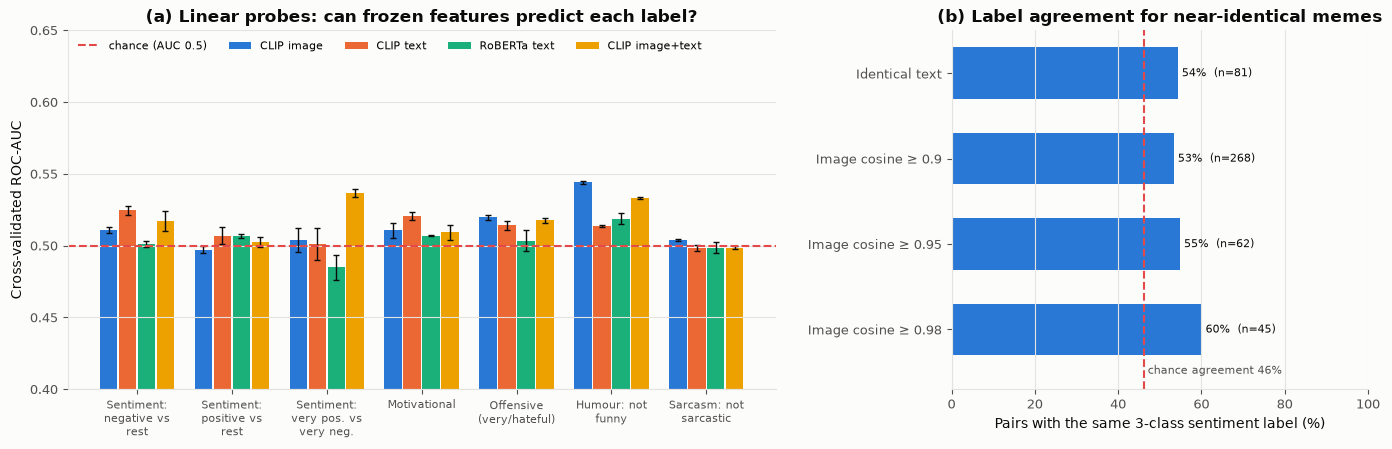

Saved fig13_label_reliability.png, label_probe_auc.csv, label_agreement.csv


In [5]:
AGREE = RL.label_agreement(FEATS["clip_img"], df)
display(AGREE.round(1))
AGREE.to_csv(cfg.table_dir / "label_agreement.csv", index=False)
RL.plot_reliability(PROBE, AGREE, cfg.fig_dir / "fig13_label_reliability.png"); plt.show()

(cfg.out / "reliability_summary.json").write_text(json.dumps(
    {"retrieval": RET, "probe": PROBE.to_dict("records"), "agreement": AGREE.to_dict("records")}, indent=1))
print("Saved fig13_label_reliability.png, label_probe_auc.csv, label_agreement.csv")